# Prediksi Minat Beli Pengunjung Toko Online
**Tujuan:** memprediksi apakah pengunjung akan membeli (`Revenue` = True/False) dari data perilaku browsing, lalu mengelompokkan pengunjung ke segmen.

**Output akhir:**
1. Model klasifikasi terbaik (disimpan sebagai `model_prediksi_belanja.joblib`)
2. Fitur paling berpengaruh terhadap pembelian
3. Segmen pengunjung (K-Means) + rekomendasi bisnis
4. Aplikasi Streamlit sederhana (`app.py`) untuk mencoba model

**Alur:** Setup → EDA → Cleaning → Split → Preprocessing → Baseline → Evaluasi → Imbalance → Tuning → Ensemble → ANN → Perbandingan → Interpretasi → Segmentasi → Simpan Model → Aplikasi

## 0. Setup
Import library dan atur lokasi dataset.

In [ ]:
# %pip install numpy pandas scikit-learn matplotlib seaborn xgboost joblib streamlit

import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, RocCurveDisplay, PrecisionRecallDisplay,
                             silhouette_score)
from sklearn.inspection import permutation_importance

DATA_PATH = 'datasetshope/online_shoppers_intention.csv'   # sesuaikan lokasi file
SEED = 42
sns.set_style('whitegrid')
print('Setup selesai')

Setup selesai


## 1. Definisi Masalah & Load Data
**Target:** `Revenue` (beli / tidak). **Fitur:** perilaku halaman, bounce/exit rate, bulan, tipe pengunjung, dll.

In [2]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 2. EDA (Exploratory Data Analysis)
ngenalin data => tipe, missing, duplikat, distribusi target, dan hubungan fitur dengan pembelian.

In [26]:
df.info()
print('\nMissing value:\n', df.isna().sum()[df.isna().sum() > 0])
print('Duplikat:', df.duplicated().sum())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 12205 entries, 0 to 12204
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12205 non-null  int64  
 1   Administrative_Duration  12205 non-null  float64
 2   Informational            12205 non-null  int64  
 3   Informational_Duration   12205 non-null  float64
 4   ProductRelated           12205 non-null  int64  
 5   ProductRelated_Duration  12205 non-null  float64
 6   BounceRates              12205 non-null  float64
 7   ExitRates                12205 non-null  float64
 8   PageValues               12205 non-null  float64
 9   SpecialDay               12205 non-null  float64
 10  Month                    12205 non-null  str    
 11  OperatingSystems         12205 non-null  str    
 12  Browser                  12205 non-null  str    
 13  Region                   12205 non-null  str    
 14  TrafficType              12205 no

,count,mean,std,min,25%,50%,75%,max
Administrative,12205.0,2.338878,3.330436,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12205.0,81.646331,177.491845,0.0,0.000000,9.000000,94.700000,3398.750000
Informational,12205.0,0.508726,1.275617,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12205.0,34.825454,141.424807,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12205.0,32.045637,44.593649,0.0,8.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12205.0,1206.982457,1919.601400,0.0,193.000000,608.942857,1477.154762,63973.522230
BounceRates,12205.0,0.020370,0.045255,0.0,0.000000,0.002899,0.016667,0.200000
ExitRates,12205.0,0.041466,0.046163,0.0,0.014231,0.025000,0.048529,0.200000
PageValues,12205.0,5.949574,18.653671,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12205.0,0.061942,0.199666,0.0,0.000000,0.000000,0.000000,1.000000


Revenue
0    0.844
1    0.156
Name: proportion, dtype: float64


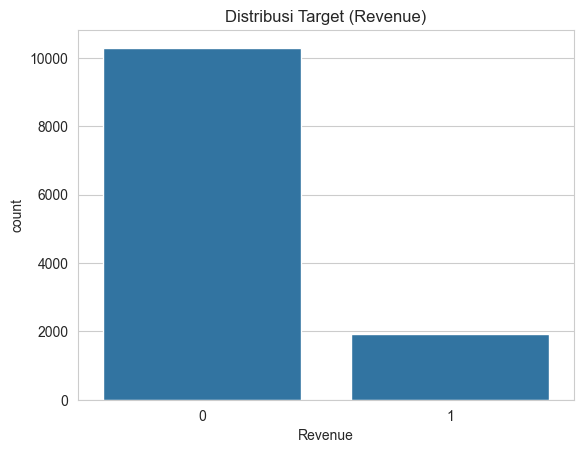

In [27]:
# Distribusi target -> cek imbalance
print(df['Revenue'].value_counts(normalize=True).round(3))
sns.countplot(x='Revenue', data=df)
plt.title('Distribusi Target (Revenue)'); plt.show()

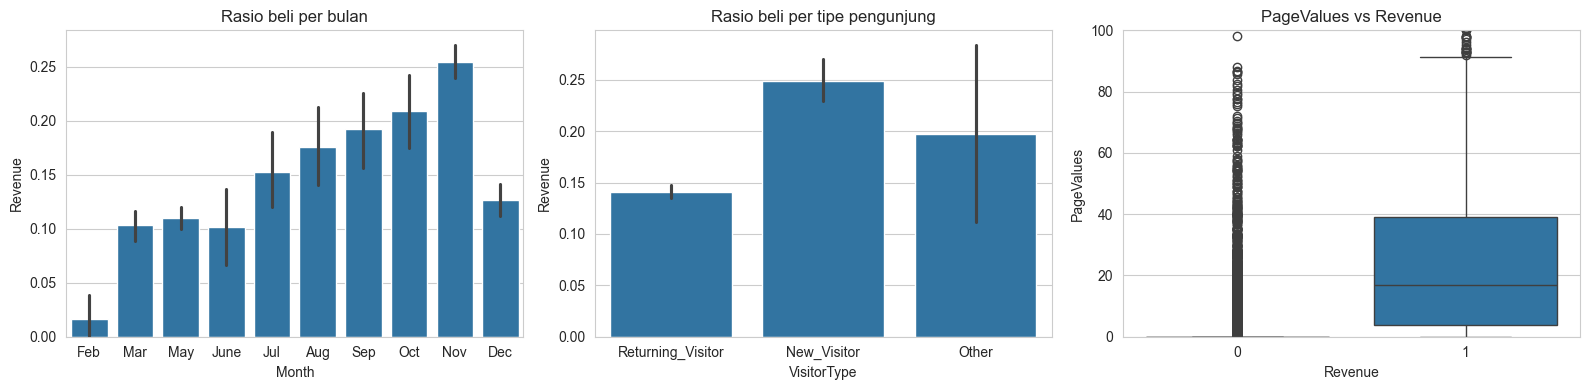

In [28]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.barplot(x='Month', y='Revenue', data=df, ax=ax[0], order=['Feb','Mar','May','June','Jul','Aug','Sep','Oct','Nov','Dec'])
ax[0].set_title('Rasio beli per bulan')
sns.barplot(x='VisitorType', y='Revenue', data=df, ax=ax[1]); ax[1].set_title('Rasio beli per tipe pengunjung')
sns.boxplot(x='Revenue', y='PageValues', data=df, ax=ax[2]); ax[2].set_ylim(0, 100); ax[2].set_title('PageValues vs Revenue')
plt.tight_layout(); plt.show()

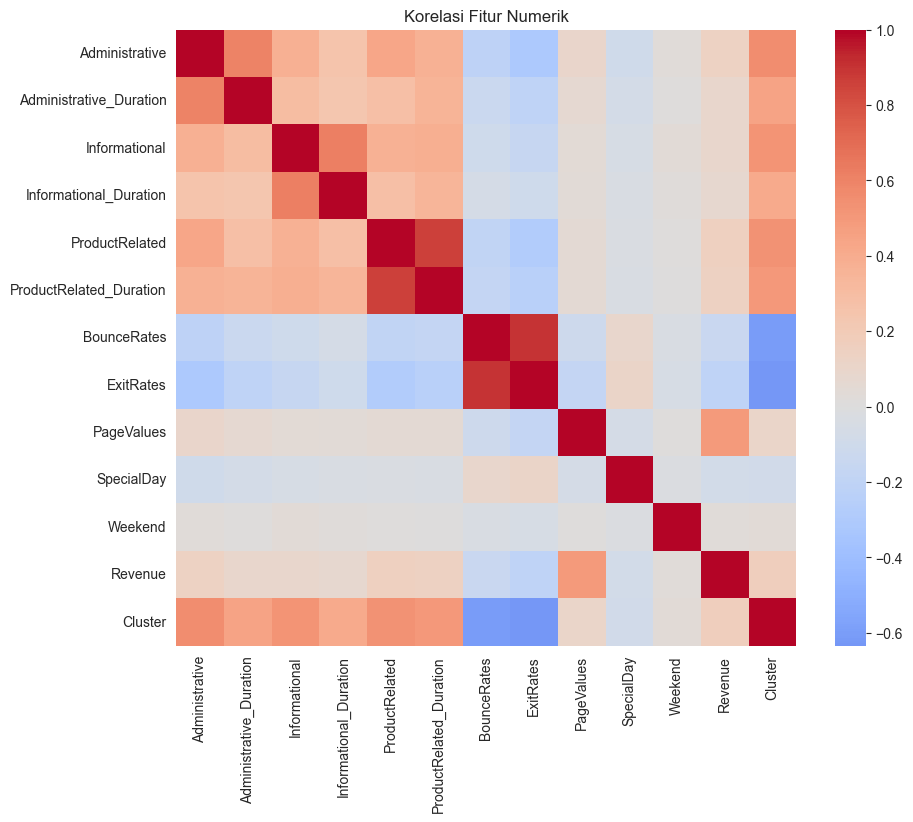

In [29]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.select_dtypes('number').assign(Revenue=df['Revenue'].astype(int)).corr(), cmap='coolwarm', center=0)
plt.title('Korelasi Fitur Numerik'); plt.show()

## 3. Data Cleaning
Hapus duplikat, ubah tipe data. Kolom kode (`OperatingSystems`, `Browser`, `Region`, `TrafficType`) adalah **kategori**, bukan angka berurutan.

In [7]:
df = df.drop_duplicates().reset_index(drop=True)
df['Revenue'] = df['Revenue'].astype(int)
df['Weekend'] = df['Weekend'].astype(int)

cat_cols = ['Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
df[cat_cols] = df[cat_cols].astype(str)
num_cols = [c for c in df.columns if c not in cat_cols + ['Revenue']]

print('Ukuran setelah cleaning:', df.shape)
print('Kolom numerik :', num_cols)
print('Kolom kategori:', cat_cols)

Ukuran setelah cleaning: (12205, 18)
Kolom numerik : ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Weekend']
Kolom kategori: ['Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']


## 4. Data Splitting
Bagi 80% latih / 20% uji. `stratify=y` menjaga proporsi pembeli tetap sama di kedua bagian.

In [8]:
X = df.drop('Revenue', axis=1)
y = df['Revenue']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
print(X_train.shape, X_test.shape)
print('Rasio beli train/test:', round(y_train.mean(), 3), round(y_test.mean(), 3))

(9764, 17) (2441, 17)
Rasio beli train/test: 0.156 0.156


## 5. Preprocessing (Pipeline)
Scaling untuk numerik + One-Hot untuk kategori. Dibungkus pipeline agar scaler **hanya belajar dari data latih** (tanpa kebocoran data).

In [11]:
def make_preprocess():
    return ColumnTransformer([
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ])

def make_pipe(model):
    return Pipeline([('prep', make_preprocess()), ('model', model)])

## 6. Baseline Model
Tiga algoritma klasik (Modul 2): **Random Forest** (aturan keputusan), **KNN** (kemiripan), **SVM** (batas pemisah). Dibandingkan dengan cross-validation, metrik F1.

In [12]:
baseline = {
    'Random Forest': make_pipe(RandomForestClassifier(random_state=SEED)),
    'KNN':           make_pipe(KNeighborsClassifier()),
    'SVM':           make_pipe(SVC(random_state=SEED)),
}
for name, pipe in baseline.items():
    f1 = cross_val_score(pipe, X_train, y_train, cv=5, scoring='f1', n_jobs=-1)
    print(f'{name:15s} F1 CV = {f1.mean():.3f}')

Random Forest   F1 CV = 0.620
KNN             F1 CV = 0.484
SVM             F1 CV = 0.587


## 7. Evaluasi yang Benar
Akurasi menipu pada data tidak seimbang. Pakai **Precision, Recall, F1, ROC-AUC, PR-AUC**. Semua hasil dicatat di tabel `results`.

In [13]:
results = {}
fitted = {}

def evaluate(name, pipe):
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    score = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, 'predict_proba') else pipe.decision_function(X_test)
    results[name] = {
        'Precision': precision_score(y_test, pred), 'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred), 'ROC-AUC': roc_auc_score(y_test, score),
        'PR-AUC': average_precision_score(y_test, score)
    }
    fitted[name] = pipe
    return pred

for name, pipe in baseline.items():
    evaluate(name + ' (baseline)', pipe)
pd.DataFrame(results).T.round(3)

,Precision,Recall,F1,ROC-AUC,PR-AUC
Random Forest (baseline),0.771,0.565,0.653,0.928,0.743
KNN (baseline),0.667,0.398,0.498,0.798,0.491
SVM (baseline),0.737,0.513,0.605,0.873,0.683


              precision    recall  f1-score   support

  Tidak beli       0.92      0.97      0.95      2059
        Beli       0.77      0.57      0.65       382

    accuracy                           0.91      2441
   macro avg       0.85      0.77      0.80      2441
weighted avg       0.90      0.91      0.90      2441



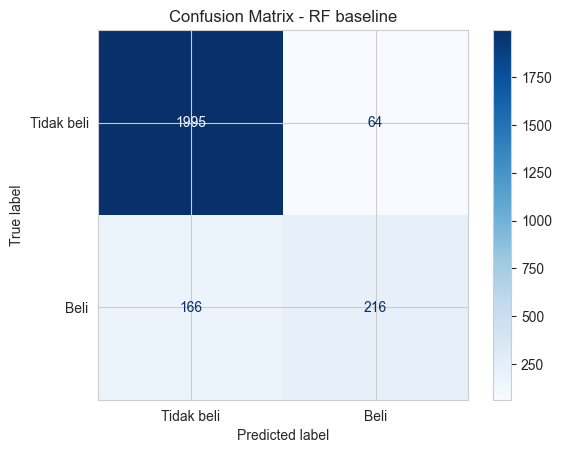

In [14]:
pred = fitted['Random Forest (baseline)'].predict(X_test)
print(classification_report(y_test, pred, target_names=['Tidak beli', 'Beli']))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['Tidak beli', 'Beli'], cmap='Blues')
plt.title('Confusion Matrix - RF baseline'); plt.show()

## 8. Menangani Imbalance
Pembeli hanya ±15%. `class_weight='balanced'` membuat model lebih peduli kelas minoritas (pembeli).

In [15]:
balanced = {
    'Random Forest (balanced)': make_pipe(RandomForestClassifier(class_weight='balanced', random_state=SEED)),
    'SVM (balanced)':           make_pipe(SVC(class_weight='balanced', random_state=SEED)),
}
for name, pipe in balanced.items():
    evaluate(name, pipe)
pd.DataFrame(results).T.round(3)

,Precision,Recall,F1,ROC-AUC,PR-AUC
Random Forest (baseline),0.771,0.565,0.653,0.928,0.743
KNN (baseline),0.667,0.398,0.498,0.798,0.491
SVM (baseline),0.737,0.513,0.605,0.873,0.683
Random Forest (balanced),0.735,0.529,0.615,0.918,0.723
SVM (balanced),0.561,0.775,0.651,0.908,0.664


## 9. Hyperparameter Tuning
Cari parameter Random Forest terbaik dengan `RandomizedSearchCV` (skor F1).

In [16]:
param_dist = {
    'model__n_estimators': [200, 300, 500],
    'model__max_depth': [None, 8, 12, 20],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': ['sqrt', 'log2'],
}
search = RandomizedSearchCV(
    make_pipe(RandomForestClassifier(class_weight='balanced', random_state=SEED)),
    param_dist, n_iter=15, cv=3, scoring='f1', random_state=SEED, n_jobs=-1)
search.fit(X_train, y_train)
print('Parameter terbaik:', search.best_params_)
print('F1 CV terbaik   :', round(search.best_score_, 3))

fitted['Random Forest (tuned)'] = search.best_estimator_
evaluate('Random Forest (tuned)', search.best_estimator_)
pd.DataFrame(results).T.round(3)

Parameter terbaik: {'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': None}
F1 CV terbaik   : 0.683


,Precision,Recall,F1,ROC-AUC,PR-AUC
Random Forest (baseline),0.771,0.565,0.653,0.928,0.743
KNN (baseline),0.667,0.398,0.498,0.798,0.491
SVM (baseline),0.737,0.513,0.605,0.873,0.683
Random Forest (balanced),0.735,0.529,0.615,0.918,0.723
SVM (balanced),0.561,0.775,0.651,0.908,0.664
Random Forest (tuned),0.637,0.730,0.680,0.927,0.723


## 10. Ensemble Boosting (XGBoost)
Boosting membangun pohon bertahap, tiap pohon memperbaiki kesalahan sebelumnya. `scale_pos_weight` menangani imbalance.

In [17]:
try:
    from xgboost import XGBClassifier
    spw = (y_train == 0).sum() / (y_train == 1).sum()
    boost = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                          colsample_bytree=0.8, scale_pos_weight=spw, eval_metric='logloss',
                          random_state=SEED, n_jobs=-1)
    boost_name = 'XGBoost'
except ImportError:   # cadangan jika xgboost belum terpasang
    from sklearn.ensemble import HistGradientBoostingClassifier
    boost = HistGradientBoostingClassifier(class_weight='balanced', random_state=SEED)
    boost_name = 'HistGradientBoosting'

evaluate(boost_name, make_pipe(boost))
pd.DataFrame(results).T.round(3)

,Precision,Recall,F1,ROC-AUC,PR-AUC
Random Forest (baseline),0.771,0.565,0.653,0.928,0.743
KNN (baseline),0.667,0.398,0.498,0.798,0.491
SVM (baseline),0.737,0.513,0.605,0.873,0.683
Random Forest (balanced),0.735,0.529,0.615,0.918,0.723
SVM (balanced),0.561,0.775,0.651,0.908,0.664
Random Forest (tuned),0.637,0.730,0.680,0.927,0.723
XGBoost,0.554,0.835,0.666,0.935,0.752


## 11. Neural Network (ANN / MLP)
Jaringan saraf 2 hidden layer (Modul 2-3). `early_stopping` mencegah overfitting.

In [18]:
mlp = make_pipe(MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=500, random_state=SEED))
evaluate('ANN (MLP)', mlp)
pd.DataFrame(results).T.round(3)

,Precision,Recall,F1,ROC-AUC,PR-AUC
Random Forest (baseline),0.771,0.565,0.653,0.928,0.743
KNN (baseline),0.667,0.398,0.498,0.798,0.491
SVM (baseline),0.737,0.513,0.605,0.873,0.683
Random Forest (balanced),0.735,0.529,0.615,0.918,0.723
SVM (balanced),0.561,0.775,0.651,0.908,0.664
Random Forest (tuned),0.637,0.730,0.680,0.927,0.723
XGBoost,0.554,0.835,0.666,0.935,0.752
ANN (MLP),0.694,0.581,0.632,0.922,0.711


## 12. Perbandingan Semua Model
Model terbaik dipilih berdasarkan **F1** (keseimbangan precision & recall untuk kelas pembeli).

,Precision,Recall,F1,ROC-AUC,PR-AUC
Random Forest (tuned),0.637,0.730,0.680,0.927,0.723
XGBoost,0.554,0.835,0.666,0.935,0.752
Random Forest (baseline),0.771,0.565,0.653,0.928,0.743
SVM (balanced),0.561,0.775,0.651,0.908,0.664
ANN (MLP),0.694,0.581,0.632,0.922,0.711
Random Forest (balanced),0.735,0.529,0.615,0.918,0.723
SVM (baseline),0.737,0.513,0.605,0.873,0.683
KNN (baseline),0.667,0.398,0.498,0.798,0.491


Model terbaik: Random Forest (tuned)


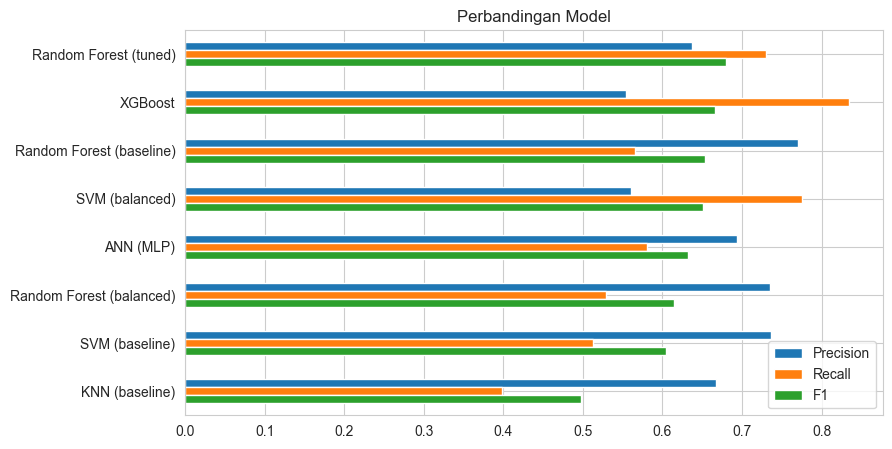

In [19]:
res = pd.DataFrame(results).T.sort_values('F1', ascending=False).round(3)
display(res)

best_name = res.index[0]
best_model = fitted[best_name]
print('Model terbaik:', best_name)

res[['Precision', 'Recall', 'F1']].plot(kind='barh', figsize=(9, 5)).invert_yaxis()
plt.title('Perbandingan Model'); plt.show()

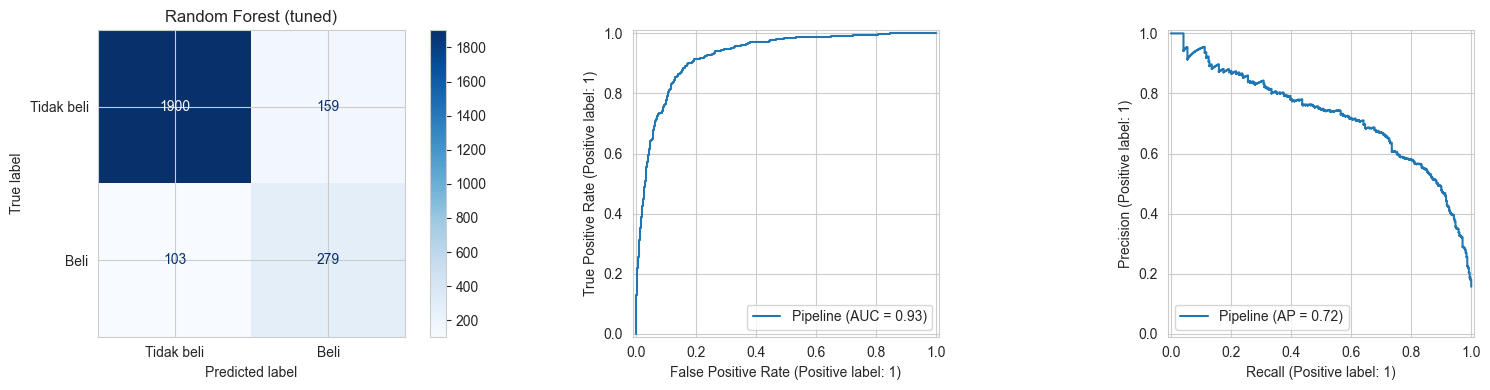

              precision    recall  f1-score   support

  Tidak beli       0.95      0.92      0.94      2059
        Beli       0.64      0.73      0.68       382

    accuracy                           0.89      2441
   macro avg       0.79      0.83      0.81      2441
weighted avg       0.90      0.89      0.90      2441



In [20]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
pred = best_model.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['Tidak beli', 'Beli'], cmap='Blues', ax=ax[0])
RocCurveDisplay.from_estimator(best_model, X_test, y_test, ax=ax[1])
PrecisionRecallDisplay.from_estimator(best_model, X_test, y_test, ax=ax[2])
ax[0].set_title(best_name); plt.tight_layout(); plt.show()
print(classification_report(y_test, pred, target_names=['Tidak beli', 'Beli']))

## 13. Interpretasi Model
Fitur apa yang paling menentukan pembelian? Dihitung dengan *permutation importance* (seberapa turun F1 jika fitur diacak).

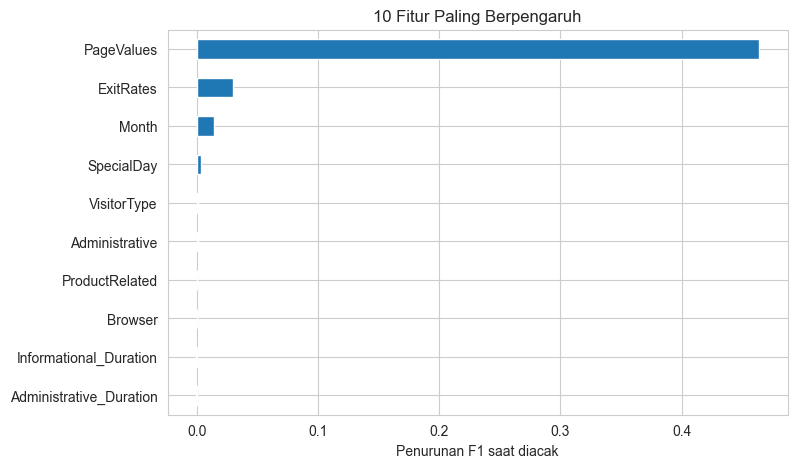

In [21]:
perm = permutation_importance(best_model, X_test, y_test, scoring='f1', n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
imp.head(10).sort_values().plot(kind='barh', figsize=(8, 5))
plt.title('10 Fitur Paling Berpengaruh'); plt.xlabel('Penurunan F1 saat diacak'); plt.show()

## 14. Segmentasi Pengunjung (K-Means)
Unsupervised (Modul 2): kelompokkan pengunjung berdasarkan perilaku browsing, lalu lihat profil dan rasio belinya.

Silhouette per k: {2: 0.476, 3: 0.505, 4: 0.402, 5: 0.414, 6: 0.412, 7: 0.377}


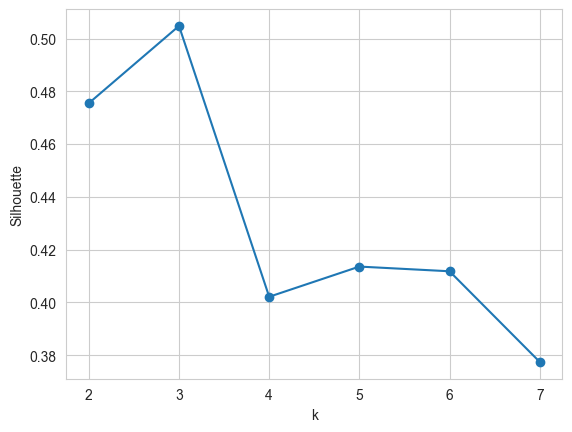

In [22]:
behav = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
         'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues']
Xb = StandardScaler().fit_transform(df[behav])

sil = {}
for k in range(2, 8):
    labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(Xb)
    sil[k] = silhouette_score(Xb, labels, sample_size=3000, random_state=SEED)
print('Silhouette per k:', {k: round(v, 3) for k, v in sil.items()})
plt.plot(list(sil), list(sil.values()), marker='o'); plt.xlabel('k'); plt.ylabel('Silhouette'); plt.show()

In [23]:
K = max(sil, key=sil.get)          # k dengan silhouette tertinggi (boleh diganti manual)
df['Cluster'] = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit_predict(Xb)

profil = df.groupby('Cluster')[behav + ['Revenue']].mean().round(2)
profil['Jumlah'] = df['Cluster'].value_counts().sort_index()
profil.rename(columns={'Revenue': 'Rasio_Beli'}, inplace=True)
profil

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,Rasio_Beli,Jumlah
Cluster,,,,,,,,,,,
0,0.05,1.62,0.02,0.10,3.23,63.40,0.16,0.18,0.00,0.01,921
1,1.71,51.24,0.22,8.24,23.88,874.11,0.01,0.03,5.89,0.15,9662
2,7.38,308.21,2.52,212.90,97.05,3839.22,0.01,0.02,9.68,0.28,1622


**Rekomendasi bisnis (isi setelah melihat profil):** beri nama tiap cluster (mis. *Penjelajah*, *Calon pembeli*, *Pengunjung sekilas*) dan tentukan strategi, mis. promo untuk cluster dengan durasi tinggi tapi rasio beli rendah.

## 15. Simpan Model
Simpan pipeline terbaik + nilai default fitur agar bisa dipakai aplikasi.

In [24]:
defaults = {c: float(X_train[c].median()) for c in num_cols}
defaults.update({c: X_train[c].mode()[0] for c in cat_cols})

joblib.dump({'model': best_model, 'name': best_name, 'features': list(X.columns),
             'defaults': defaults, 'months': sorted(df['Month'].unique()),
             'visitor_types': sorted(df['VisitorType'].unique())},
            'model_prediksi_belanja.joblib')
print('Tersimpan: model_prediksi_belanja.joblib  ->', best_name)

Tersimpan: model_prediksi_belanja.joblib  -> Random Forest (tuned)


## 16. Aplikasi Streamlit
Tulis `app.py`, lalu jalankan di terminal: `streamlit run app.py`.

In [25]:
%%writefile app.py
import joblib, pandas as pd, streamlit as st

art = joblib.load('model_prediksi_belanja.joblib')
st.title('Prediksi Minat Beli Pengunjung')
st.caption(f"Model: {art['name']}")

col1, col2 = st.columns(2)
with col1:
    product = st.number_input('Jumlah halaman produk dilihat', 0, 500, 20)
    product_dur = st.number_input('Durasi halaman produk (detik)', 0.0, 20000.0, 600.0)
    page_values = st.number_input('PageValues', 0.0, 400.0, 0.0)
with col2:
    bounce = st.slider('BounceRates', 0.0, 0.2, 0.02)
    exit_ = st.slider('ExitRates', 0.0, 0.2, 0.04)
    month = st.selectbox('Bulan', art['months'])
    vtype = st.selectbox('Tipe pengunjung', art['visitor_types'])
    weekend = st.checkbox('Akhir pekan')

if st.button('Prediksi'):
    row = dict(art['defaults'])
    row.update({'ProductRelated': product, 'ProductRelated_Duration': product_dur,
                'PageValues': page_values, 'BounceRates': bounce, 'ExitRates': exit_,
                'Month': month, 'VisitorType': vtype, 'Weekend': int(weekend)})
    X_new = pd.DataFrame([row])[art['features']]
    m = art['model']
    if hasattr(m, 'predict_proba'):
        st.metric('Peluang membeli', f"{m.predict_proba(X_new)[0, 1]:.1%}")
    st.success('Cenderung MEMBELI' if m.predict(X_new)[0] == 1 else 'Cenderung TIDAK membeli')

Writing app.py


## 17. Kesimpulan
Isi dengan hasil kamu sendiri:
- **Model terbaik:** … (F1 = …, Recall = …)
- **Fitur paling berpengaruh:** …
- **Segmen pengunjung:** …
- **Rekomendasi bisnis:** …
- **Keterbatasan & pengembangan lanjut:** data hanya 1 tahun, tidak ada urutan waktu per pengunjung; bisa dicoba SMOTE, LightGBM, atau threshold tuning.